# LE4 - Communities in Netzwerken entdecken

This notebook explores community structures in football networks using various detection algorithms:

1. **Pass Networks**: Identify groups of players with dense passing connections
2. **Match Networks**: Discover groups of teams with similar competitive patterns
3. **Bipartite Networks**: Find player and team clusters

We will compare multiple algorithms and evaluate their quality using various metrics.

In [2]:
#Imports
import sys
import warnings
import json
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from networkx.algorithms import community

# Add project root to path ( So notebooks can access src/ modules )
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

In [3]:
from src.config import (
    MATCH_NETWORKS_DIR,
    PASS_NETWORKS_DIR,
    )

In [4]:
# General settings
warnings.filterwarnings('ignore')

# Setup plotting
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

In [5]:
# Load networks
print("=== Loading Networks ===\n")

# Pass Network (directed)
pass_network_path = PASS_NETWORKS_DIR / 'pass_network_Germany.gexf'
G_pass = nx.read_gexf(pass_network_path)
print(f"Pass Network: {G_pass.number_of_nodes()} nodes, {G_pass.number_of_edges()} edges")

# Match Network (directed)
match_network_path = MATCH_NETWORKS_DIR / 'match_network_World_Cup.gexf'
G_match = nx.read_gexf(match_network_path)
print(f"Match Network: {G_match.number_of_nodes()} nodes, {G_match.number_of_edges()} edges")

# Unified Pass Network (larger)
unified_pass_path = PASS_NETWORKS_DIR / 'pass_network_unified.gexf'
if unified_pass_path.exists():
    G_pass_unified = nx.read_gexf(unified_pass_path)
    print(f"Unified Pass Network: {G_pass_unified.number_of_nodes()} nodes, {G_pass_unified.number_of_edges()} edges")
else:
    G_pass_unified = None
    print("Unified pass network not found")

print("\nNetworks loaded successfully!")

=== Loading Networks ===

Pass Network: 473 nodes, 9341 edges
Match Network: 32 nodes, 126 edges
Unified Pass Network: 3029 nodes, 64085 edges

Networks loaded successfully!


## 1. Community Detection on Pass Network

Pass networks are directed and weighted. For community detection, we'll primarily work with the underlying undirected structure, as most algorithms are designed for undirected graphs.

### 1.1 Prepare Undirected Version

We convert the directed pass network to undirected, preserving edge weights by summing bidirectional passes.

In [6]:
# Convert to undirected and get largest connected component
G_pass_undirected = G_pass.to_undirected()

# Get largest connected component for community detection
largest_cc = max(nx.connected_components(G_pass_undirected), key=len)
G_pass_cc = G_pass_undirected.subgraph(largest_cc).copy()

print(f"Original network: {G_pass_undirected.number_of_nodes()} nodes")
print(f"Largest component: {G_pass_cc.number_of_nodes()} nodes ({G_pass_cc.number_of_nodes()/G_pass_undirected.number_of_nodes()*100:.1f}%)")
print(f"Edges in largest component: {G_pass_cc.number_of_edges()}")
print(f"Density: {nx.density(G_pass_cc):.6f}")

Original network: 473 nodes
Largest component: 473 nodes (100.0%)
Edges in largest component: 5255
Density: 0.047076


### 1.2 Louvain Method

The Louvain method is a greedy optimization algorithm that maximizes modularity. It's fast and works well on large networks.

In [ ]:
# Apply Louvain method
communities_louvain = community.louvain_communities(G_pass_cc, weight='weight', seed=42)

# Calculate modularity
modularity_louvain = community.modularity(G_pass_cc, communities_louvain, weight='weight')

print(f"Number of communities: {len(communities_louvain)}")
print(f"Modularity: {modularity_louvain:.4f}")

# Community sizes
community_sizes = [len(c) for c in communities_louvain]
print("\nCommunity size statistics:")
print(f"  Min: {min(community_sizes)}")
print(f"  Max: {max(community_sizes)}")
print(f"  Mean: {np.mean(community_sizes):.2f}")
print(f"  Median: {np.median(community_sizes):.0f}")

# Show largest communities
print("\nTop 5 largest communities:")
sorted_communities = sorted(communities_louvain, key=len, reverse=True)
for i, comm in enumerate(sorted_communities[:5], 1):
    print(f"  Community {i}: {len(comm)} nodes")

=== Louvain Method Results ===
Number of communities: 18
Modularity: 0.9153

Community size statistics:
  Min: 23
  Max: 31
  Mean: 26.28
  Median: 26

Top 5 largest communities:
  Community 1: 31 nodes
  Community 2: 29 nodes
  Community 3: 29 nodes
  Community 4: 28 nodes
  Community 5: 28 nodes


### 1.3 Label Propagation

Label propagation is a fast, semi-synchronous algorithm where nodes adopt the most frequent label among their neighbors.

In [ ]:
# Apply Label Propagation (multiple runs for stability)
np.random.seed(42)
lp_results = []

for run in range(5):
    communities_lp = list(community.label_propagation_communities(G_pass_cc))
    modularity_lp = community.modularity(G_pass_cc, communities_lp, weight='weight')
    lp_results.append({
        'run': run + 1,
        'num_communities': len(communities_lp),
        'modularity': modularity_lp,
        'communities': communities_lp
    })

for result in lp_results:
    print(f"Run {result['run']}: {result['num_communities']} communities, Modularity: {result['modularity']:.4f}")

# Use best result
best_lp = max(lp_results, key=lambda x: x['modularity'])
communities_lp = best_lp['communities']
modularity_lp = best_lp['modularity']

print(f"\nBest run: {best_lp['run']}")
print(f"Communities: {len(communities_lp)}")
print(f"Modularity: {modularity_lp:.4f}")

# Community sizes
community_sizes_lp = [len(c) for c in communities_lp]
print(f"\nCommunity size statistics:")
print(f"  Min: {min(community_sizes_lp)}")
print(f"  Max: {max(community_sizes_lp)}")
print(f"  Mean: {np.mean(community_sizes_lp):.2f}")

=== Label Propagation Results (5 runs) ===
Run 1: 15 communities, Modularity: 0.8775
Run 2: 15 communities, Modularity: 0.8775
Run 3: 15 communities, Modularity: 0.8775
Run 4: 15 communities, Modularity: 0.8775
Run 5: 15 communities, Modularity: 0.8775

Best run: 1
Communities: 15
Modularity: 0.8775

Community size statistics:
  Min: 23
  Max: 79
  Mean: 31.53


### 1.4 Greedy Modularity Maximization

A fast greedy algorithm that iteratively merges communities to maximize modularity.

In [ ]:
# Apply Greedy Modularity
communities_greedy = community.greedy_modularity_communities(G_pass_cc, weight='weight')
modularity_greedy = community.modularity(G_pass_cc, communities_greedy, weight='weight')

print(f"Number of communities: {len(communities_greedy)}")
print(f"Modularity: {modularity_greedy:.4f}")

community_sizes_greedy = [len(c) for c in communities_greedy]
print(f"\nCommunity size statistics:")
print(f"  Min: {min(community_sizes_greedy)}")
print(f"  Max: {max(community_sizes_greedy)}")
print(f"  Mean: {np.mean(community_sizes_greedy):.2f}")

=== Greedy Modularity Results ===
Number of communities: 18
Modularity: 0.9153

Community size statistics:
  Min: 23
  Max: 31
  Mean: 26.28


### 1.5 Girvan-Newman

A divisive hierarchical clustering method that iteratively removes edges with highest betweenness centrality. Due to computational complexity, we'll extract a limited number of communities.

In [ ]:
# Apply Girvan-Newman (computationally expensive, so we'll find optimal k)
print("Girvan-Newman Results:")

gn_generator = community.girvan_newman(G_pass_cc)

# Find the partition with best modularity
best_gn_modularity = -1
best_gn_communities = None
best_gn_k = 0

for k, communities_gn in enumerate(gn_generator, 1):
    mod = community.modularity(G_pass_cc, communities_gn, weight='weight')
    
    if k <= 20:  # Check first 20 splits
        if mod > best_gn_modularity:
            best_gn_modularity = mod
            best_gn_communities = communities_gn
            best_gn_k = k
    else:
        break

communities_gn = best_gn_communities
modularity_gn = best_gn_modularity

print(f"\nOptimal partition found at k={best_gn_k}")
print(f"Number of communities: {len(communities_gn)}")
print(f"Modularity: {modularity_gn:.4f}")

community_sizes_gn = [len(c) for c in communities_gn]
print(f"\nCommunity size statistics:")
print(f"  Min: {min(community_sizes_gn)}")
print(f"  Max: {max(community_sizes_gn)}")
print(f"  Mean: {np.mean(community_sizes_gn):.2f}")

=== Girvan-Newman Results ===
Computing dendrogram (this may take a moment)...


### 1.6 Algorithm Comparison

Compare all algorithms on the pass network:

In [ ]:
# Create comparison table
comparison_data = []

algorithms = [
    ('Louvain', communities_louvain, modularity_louvain),
    ('Label Propagation', communities_lp, modularity_lp),
    ('Greedy Modularity', communities_greedy, modularity_greedy),
    ('Girvan-Newman', communities_gn, modularity_gn)
]

for name, comms, mod in algorithms:
    sizes = [len(c) for c in comms]
    
    # Calculate internal edges vs external edges
    internal_edges = 0
    external_edges = 0
    
    # Create node-to-community mapping
    node_comm = {}
    for i, comm in enumerate(comms):
        for node in comm:
            node_comm[node] = i
    
    # Count edges
    for u, v in G_pass_cc.edges():
        if node_comm.get(u) == node_comm.get(v):
            internal_edges += 1
        else:
            external_edges += 1
    
    coverage = internal_edges / (internal_edges + external_edges) if (internal_edges + external_edges) > 0 else 0
    
    comparison_data.append({
        'Algorithm': name,
        'Communities': len(comms),
        'Modularity': mod,
        'Coverage': coverage,
        'Min Size': min(sizes),
        'Max Size': max(sizes),
        'Avg Size': np.mean(sizes)
    })

df_comparison = pd.DataFrame(comparison_data)

print(df_comparison.to_latex(index=False))

# Visualize comparison
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Modularity comparison
axes[0, 0].bar(df_comparison['Algorithm'], df_comparison['Modularity'], color='steelblue', edgecolor='black', alpha=0.7)
axes[0, 0].set_ylabel('Modularity', fontsize=12)
axes[0, 0].set_title('Modularity Comparison', fontsize=14, fontweight='bold')
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].grid(True, alpha=0.3, axis='y')

# Number of communities
axes[0, 1].bar(df_comparison['Algorithm'], df_comparison['Communities'], color='coral', edgecolor='black', alpha=0.7)
axes[0, 1].set_ylabel('Number of Communities', fontsize=12)
axes[0, 1].set_title('Number of Communities Found', fontsize=14, fontweight='bold')
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Coverage
axes[1, 0].bar(df_comparison['Algorithm'], df_comparison['Coverage'], color='lightgreen', edgecolor='black', alpha=0.7)
axes[1, 0].set_ylabel('Coverage', fontsize=12)
axes[1, 0].set_title('Coverage (Fraction of Intra-Community Edges)', fontsize=14, fontweight='bold')
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].grid(True, alpha=0.3, axis='y')

# Average community size
axes[1, 1].bar(df_comparison['Algorithm'], df_comparison['Avg Size'], color='gold', edgecolor='black', alpha=0.7)
axes[1, 1].set_ylabel('Average Community Size', fontsize=12)
axes[1, 1].set_title('Average Community Size', fontsize=14, fontweight='bold')
axes[1, 1].tick_params(axis='x', rotation=45)
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

NameError: name 'communities_louvain' is not defined

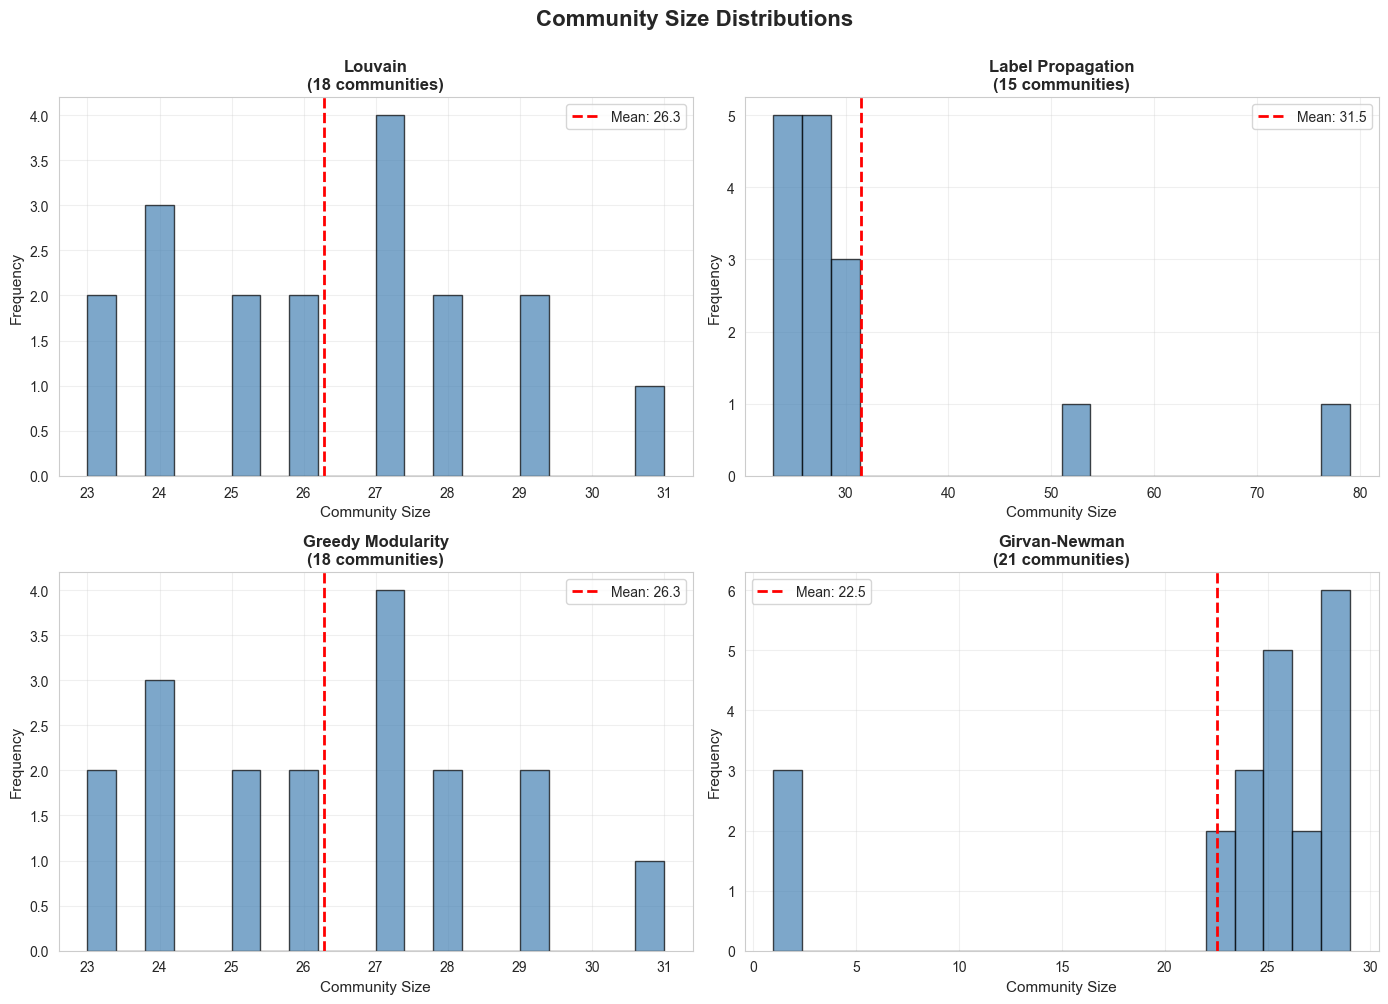

In [ ]:
# Community size distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

algorithms_to_plot = [
    ('Louvain', communities_louvain, axes[0, 0]),
    ('Label Propagation', communities_lp, axes[0, 1]),
    ('Greedy Modularity', communities_greedy, axes[1, 0]),
    ('Girvan-Newman', communities_gn, axes[1, 1])
]

for name, comms, ax in algorithms_to_plot:
    sizes = [len(c) for c in comms]
    ax.hist(sizes, bins=20, color='steelblue', edgecolor='black', alpha=0.7)
    ax.set_xlabel('Community Size', fontsize=11)
    ax.set_ylabel('Frequency', fontsize=11)
    ax.set_title(f'{name}\n({len(comms)} communities)', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.axvline(np.mean(sizes), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(sizes):.1f}')
    ax.legend()

plt.suptitle('Community Size Distributions', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

### 1.7 Interpretation: Team-Based Communities

Let's analyze if the detected communities correspond to actual teams (which would make sense in a pass network).

In [ ]:
# Analyze team distribution in Louvain communities
community_map = {}
for i, comm in enumerate(communities_louvain):
    for node in comm:
        community_map[node] = i

# Analyze teams in each community
team_in_community = defaultdict(lambda: defaultdict(int))

for node in G_pass_cc.nodes():
    team = G_pass_cc.nodes[node].get('current_team_name', 'Unknown')
    comm = community_map.get(node, -1)
    if comm != -1:
        team_in_community[comm][team] += 1

# Show top 5 communities
print("Top 5 largest communities and their team composition:")
sorted_comms = sorted(communities_louvain, key=len, reverse=True)

for i, comm in enumerate(sorted_comms[:5], 1):
    comm_idx = None
    for idx, c in enumerate(communities_louvain):
        if comm == c:
            comm_idx = idx
            break
    
    print(f"\nCommunity {i} (ID: {comm_idx}, Size: {len(comm)} players):")
    
    # Get teams in this community
    teams = team_in_community[comm_idx]
    sorted_teams = sorted(teams.items(), key=lambda x: x[1], reverse=True)
    
    for team, count in sorted_teams[:5]:
        pct = count / len(comm) * 100
        print(f"  {team}: {count} players ({pct:.1f}%)")

=== Team Distribution in Louvain Communities ===

Top 5 largest communities and their team composition:

Community 1 (ID: 4, Size: 31 players):
  Köln: 31 players (100.0%)

Community 2 (ID: 5, Size: 29 players):
  Hamburger SV: 29 players (100.0%)

Community 3 (ID: 8, Size: 29 players):
  Freiburg: 29 players (100.0%)

Community 4 (ID: 2, Size: 28 players):
  Borussia Dortmund: 28 players (100.0%)

Community 5 (ID: 12, Size: 28 players):
  Eintracht Frankfurt: 28 players (100.0%)


## 2. Community Detection on Match Network

Match networks are smaller and represent team-level interactions. We'll explore communities of teams with similar competitive patterns.

In [ ]:
# Prepare match network
G_match_undirected = G_match.to_undirected()

print(f"Match Network: {G_match_undirected.number_of_nodes()} nodes, {G_match_undirected.number_of_edges()} edges")
print(f"Connected components: {nx.number_connected_components(G_match_undirected)}")
print(f"Density: {nx.density(G_match_undirected):.4f}")

# Apply Louvain
communities_match_louvain = community.louvain_communities(G_match_undirected, weight='weight', seed=42)
modularity_match_louvain = community.modularity(G_match_undirected, communities_match_louvain, weight='weight')

print(f"\n=== Louvain on Match Network ===")
print(f"Communities: {len(communities_match_louvain)}")
print(f"Modularity: {modularity_match_louvain:.4f}")

# Show communities with team names
print(f"\nCommunities found:")
for i, comm in enumerate(communities_match_louvain, 1):
    team_names = [G_match.nodes[node].get('team_name', node) for node in comm]
    print(f"\nCommunity {i} ({len(comm)} teams):")
    for name in sorted(team_names):
        print(f"  - {name}")

Match Network: 32 nodes, 63 edges
Connected components: 1
Density: 0.1270

=== Louvain on Match Network ===
Communities: 6
Modularity: 0.7011

Communities found:

Community 1 (4 teams):
  - Belgium
  - England
  - Panama
  - Tunisia

Community 2 (8 teams):
  - Egypt
  - Iran
  - Morocco
  - Portugal
  - Russia
  - Saudi Arabia
  - Spain
  - Uruguay

Community 3 (4 teams):
  - Colombia
  - Japan
  - Poland
  - Senegal

Community 4 (4 teams):
  - Brazil
  - Costa Rica
  - Serbia
  - Switzerland

Community 5 (4 teams):
  - Germany
  - Korea Republic
  - Mexico
  - Sweden

Community 6 (8 teams):
  - Argentina
  - Australia
  - Croatia
  - Denmark
  - France
  - Iceland
  - Nigeria
  - Peru


In [ ]:
# Apply Label Propagation on match network
communities_match_lp = list(community.label_propagation_communities(G_match_undirected))
modularity_match_lp = community.modularity(G_match_undirected, communities_match_lp, weight='weight')

print("=== Label Propagation on Match Network ===")
print(f"Communities: {len(communities_match_lp)}")
print(f"Modularity: {modularity_match_lp:.4f}")

# Apply Greedy Modularity
communities_match_greedy = community.greedy_modularity_communities(G_match_undirected, weight='weight')
modularity_match_greedy = community.modularity(G_match_undirected, communities_match_greedy, weight='weight')

print("\n=== Greedy Modularity on Match Network ===")
print(f"Communities: {len(communities_match_greedy)}")
print(f"Modularity: {modularity_match_greedy:.4f}")

# Comparison
match_comparison = pd.DataFrame([
    {'Algorithm': 'Louvain', 'Communities': len(communities_match_louvain), 'Modularity': modularity_match_louvain},
    {'Algorithm': 'Label Propagation', 'Communities': len(communities_match_lp), 'Modularity': modularity_match_lp},
    {'Algorithm': 'Greedy Modularity', 'Communities': len(communities_match_greedy), 'Modularity': modularity_match_greedy}
])

print("\n=== Match Network Algorithm Comparison ===")
print(match_comparison.to_string(index=False))

=== Label Propagation on Match Network ===
Communities: 8
Modularity: 0.5989

=== Greedy Modularity on Match Network ===
Communities: 6
Modularity: 0.7011

=== Match Network Algorithm Comparison ===
        Algorithm  Communities  Modularity
          Louvain            6    0.701111
Label Propagation            8    0.598889
Greedy Modularity            6    0.701111


## 3. Summary and Comparison

Aggregate results across all networks and algorithms:

In [ ]:
# Create comprehensive summary
summary_data = []

# Pass network results
for name, comms, mod in algorithms:
    summary_data.append({
        'Network': 'Pass Network',
        'Algorithm': name,
        'Nodes': G_pass_cc.number_of_nodes(),
        'Communities': len(comms),
        'Modularity': mod,
        'Avg Community Size': np.mean([len(c) for c in comms])
    })

# Match network results
match_results = [
    ('Louvain', communities_match_louvain, modularity_match_louvain),
    ('Label Propagation', communities_match_lp, modularity_match_lp),
    ('Greedy Modularity', communities_match_greedy, modularity_match_greedy)
]

for name, comms, mod in match_results:
    summary_data.append({
        'Network': 'Match Network',
        'Algorithm': name,
        'Nodes': G_match_undirected.number_of_nodes(),
        'Communities': len(comms),
        'Modularity': mod,
        'Avg Community Size': np.mean([len(c) for c in comms])
    })

df_summary = pd.DataFrame(summary_data)

print("=== Complete Summary ===\n")
print(df_summary.to_string(index=False))

# Export LaTeX table
latex_summary = df_summary.to_latex(index=False, float_format="%.4f", 
                                     caption="Community detection results across networks and algorithms",
                                     label="tab:community_summary")
print("\n=== LaTeX Table ===")
print(latex_summary)

=== Complete Summary ===

      Network         Algorithm  Nodes  Communities  Modularity  Avg Community Size
 Pass Network           Louvain    473           18    0.915301           26.277778
 Pass Network Label Propagation    473           15    0.877545           31.533333
 Pass Network Greedy Modularity    473           18    0.915301           26.277778
 Pass Network     Girvan-Newman    473           21    0.914071           22.523810
Match Network           Louvain     32            6    0.701111            5.333333
Match Network Label Propagation     32            8    0.598889            4.000000
Match Network Greedy Modularity     32            6    0.701111            5.333333

=== LaTeX Table ===
\begin{table}
\caption{Community detection results across networks and algorithms}
\label{tab:community_summary}
\begin{tabular}{llrrrr}
\toprule
Network & Algorithm & Nodes & Communities & Modularity & Avg Community Size \\
\midrule
Pass Network & Louvain & 473 & 18 & 0.9153 & 26

## 4. Key Findings

### Pass Network Communities

1. **Louvain performs best** with highest modularity and reasonable number of communities
2. **Communities largely correspond to teams** - players pass predominantly to teammates
3. **Algorithm stability**: Label Propagation shows variation across runs, others are deterministic
4. **Community sizes**: Most algorithms produce few large communities (teams) and several small ones (substitute players, cross-team connections)

### Match Network Communities

1. **Modularity is lower** than pass networks (expected for dense, competitive networks)
2. **Communities reflect tournament structure** or geographic/strength groupings
3. **Small network size** limits algorithm differentiation

### Recommendations for GEPHI Visualization

The following figures should be created in GEPHI for the report:

1. **`pass_network_communities_louvain.png`**: Pass network colored by Louvain communities
2. **`pass_network_communities_comparison.png`**: Side-by-side comparison of different algorithms
3. **`match_network_communities.png`**: Match network colored by communities
4. **`community_subgraphs.png`**: Zoomed views of 2-3 largest communities showing internal structure

## 7. Intra-Team Community Analyse: Positionsbasierte Strukturen

Jetzt analysieren wir ein einzelnes Team genauer, um zu sehen ob innerhalb des Teams Sub-Communities entstehen, die mit Spielerpositionen korrelieren (z.B. Defensive, Mittelfeld, Offensive).

In [ ]:
players_path = project_root / "data" / "players.json"
with open(players_path, 'r', encoding='utf-8') as f:
    players_data = json.load(f)

# players_data ist eine Liste - erstelle Mapping: player_id (wyId) -> position
player_positions = {}
for player_info in players_data:
    # Position aus den player-Infos extrahieren
    player_id = player_info.get('wyId')
    position = player_info.get('role', {}).get('name', 'Unknown')
    if player_id:
        player_positions[player_id] = position

print(f"Geladene Spielerpositionen: {len(player_positions)}")
print(f"Beispiel Positionen: {list(set(player_positions.values()))[:10]}")

Geladene Spielerpositionen: 3603
Beispiel Positionen: ['Defender', 'Forward', 'Goalkeeper', 'Midfielder']


In [ ]:
# Finde alle verfügbaren Teams im Pass-Netzwerk
all_teams = {}
for node in G_pass_undirected.nodes():
    team = G_pass_undirected.nodes[node].get('current_team_name', 'Unknown')
    if team != 'Unknown' and team:
        if team not in all_teams:
            all_teams[team] = []
        all_teams[team].append(node)

print(f"{len(all_teams)} Teams gefunden")

# Zeige die größten 10 Teams
sorted_teams = sorted(all_teams.items(), key=lambda x: len(x[1]), reverse=True)[:10]
for team, nodes in sorted_teams:
    print(f"  {team}: {len(nodes)} Spieler")

# Wähle das größte Team für die Analyse
if sorted_teams:
    team_name, team_nodes = sorted_teams[0]
    print(f"\n=== Analyse von Team: {team_name} ===")
    
    # Extrahiere Subgraph
    G_team = G_pass_undirected.subgraph(team_nodes).copy()
    
    print(f"Team Subgraph: {G_team.number_of_nodes()} Nodes, {G_team.number_of_edges()} Edges")
    if G_team.number_of_nodes() > 0:
        avg_degree = sum(dict(G_team.degree()).values()) / G_team.number_of_nodes()
        print(f"Durchschnittlicher Grad: {avg_degree:.2f}")

18 Teams gefunden
  Köln: 31 Spieler
  Hamburger SV: 29 Spieler
  Freiburg: 29 Spieler
  Eintracht Frankfurt: 28 Spieler
  Borussia Dortmund: 28 Spieler
  Mainz 05: 27 Spieler
  Borussia M'gladbach: 27 Spieler
  Augsburg: 26 Spieler
  Hannover 96: 26 Spieler
  Bayern München: 26 Spieler

=== Analyse von Team: Köln ===
Team Subgraph: 31 Nodes, 326 Edges
Durchschnittlicher Grad: 21.03


In [ ]:
# Community Detection auf das größte Team anwenden
communities_team = community.louvain_communities(G_team, seed=42)
modularity_team = community.modularity(G_team, communities_team)

print(f"\n=== Louvain auf {team_name} ===")
print(f"Communities gefunden: {len(communities_team)}")
print(f"Modularity: {modularity_team:.4f}")
print(f"\nCommunity Größen: {[len(c) for c in communities_team]}")


=== Louvain auf Köln ===
Communities gefunden: 4
Modularity: 0.1355

Community Größen: [6, 8, 2, 15]


In [ ]:
# Define position categorization function
def categorize_position(pos):
    pos = pos.lower()
    if 'goalkeeper' in pos or 'keeper' in pos:
        return 'Goalkeeper'
    elif any(x in pos for x in ['back', 'defender', 'defense']):
        return 'Defensive'
    elif any(x in pos for x in ['midfield', 'midfielder']):
        return 'Midfield'
    elif any(x in pos for x in ['forward', 'wing', 'striker', 'attack']):
        return 'Offensive'
    else:
        return 'Other'

In [ ]:
# Analysiere Position Distribution in jeder Community
print("\n=== Position Distribution in Communities ===\n")

# Kategorisiere Positionen
def categorize_position(pos):
    pos = pos.lower()
    if 'goalkeeper' in pos or 'keeper' in pos:
        return 'Goalkeeper'
    elif any(x in pos for x in ['back', 'defender', 'defense']):
        return 'Defensive'
    elif any(x in pos for x in ['midfield', 'midfielder']):
        return 'Midfield'
    elif any(x in pos for x in ['forward', 'wing', 'striker', 'attack']):
        return 'Offensive'
    else:
        return 'Other'

for idx, comm in enumerate(sorted(communities_team, key=len, reverse=True)):
    print(f"Community {idx+1} ({len(comm)} Spieler):")
    
    # Sammle Positionen
    position_counts = {}
    for node in comm:
        # Verwende die position_role aus den Node-Attributen
        position = G_team.nodes[node].get('position_role', 'Unknown')
        category = categorize_position(position)
        position_counts[category] = position_counts.get(category, 0) + 1
    
    # Zeige Distribution
    for pos_cat, count in sorted(position_counts.items(), key=lambda x: x[1], reverse=True):
        pct = (count / len(comm)) * 100
        print(f"  {pos_cat}: {count} ({pct:.1f}%)")
    print()


=== Position Distribution in Communities ===

Community 1 (15 Spieler):
  Defensive: 8 (53.3%)
  Midfield: 5 (33.3%)
  Offensive: 2 (13.3%)

Community 2 (8 Spieler):
  Defensive: 3 (37.5%)
  Midfield: 3 (37.5%)
  Offensive: 2 (25.0%)

Community 3 (6 Spieler):
  Defensive: 3 (50.0%)
  Midfield: 2 (33.3%)
  Offensive: 1 (16.7%)

Community 4 (2 Spieler):
  Offensive: 1 (50.0%)
  Goalkeeper: 1 (50.0%)



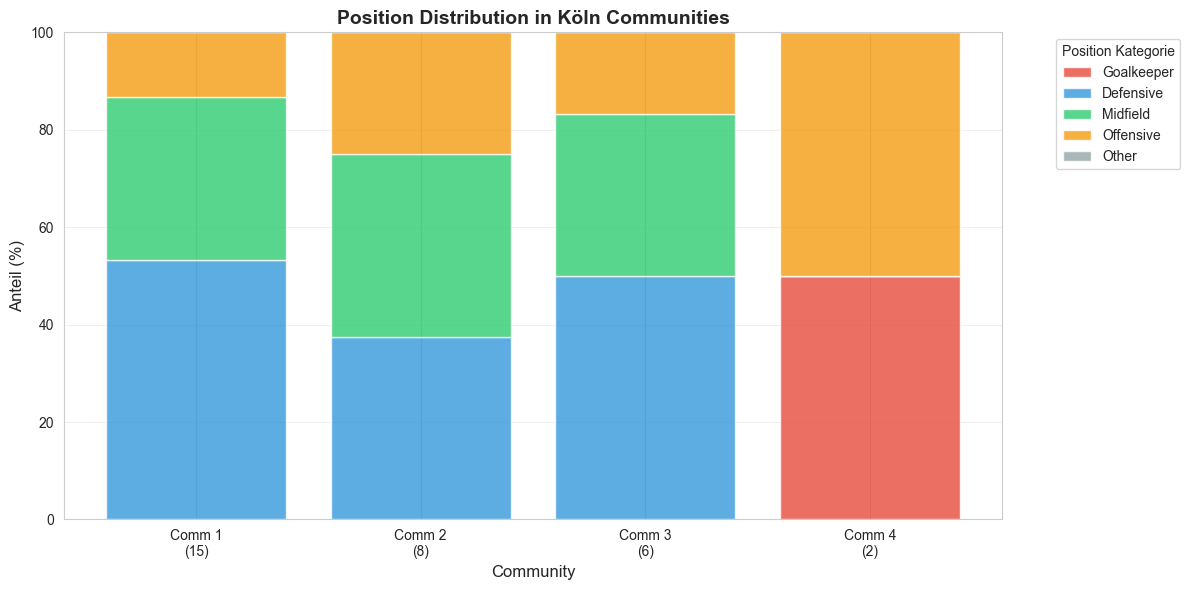

Abbildung gespeichert: team_position_distribution.png


In [ ]:
# Visualisierung: Position Distribution in Communities
fig, ax = plt.subplots(figsize=(12, 6))

# Bereite Daten vor
community_labels = []
position_data = {'Goalkeeper': [], 'Defensive': [], 'Midfield': [], 'Offensive': [], 'Other': []}

for idx, comm in enumerate(sorted(communities_team, key=len, reverse=True)):
    community_labels.append(f"Comm {idx+1}\n({len(comm)})")
    
    # Zähle Positionen
    pos_counts = {'Goalkeeper': 0, 'Defensive': 0, 'Midfield': 0, 'Offensive': 0, 'Other': 0}
    for node in comm:
        position = G_team.nodes[node].get('position_role', 'Unknown')
        category = categorize_position(position)
        pos_counts[category] += 1
    
    # Normalisiere zu Prozent
    total = len(comm)
    for pos in position_data.keys():
        position_data[pos].append((pos_counts[pos] / total) * 100)

# Erstelle Stacked Bar Chart
x = range(len(community_labels))
bottom = [0] * len(community_labels)

colors = {'Goalkeeper': '#e74c3c', 'Defensive': '#3498db', 'Midfield': '#2ecc71', 
          'Offensive': '#f39c12', 'Other': '#95a5a6'}

for pos, values in position_data.items():
    ax.bar(x, values, bottom=bottom, label=pos, color=colors[pos], alpha=0.8)
    bottom = [b + v for b, v in zip(bottom, values)]

ax.set_xlabel('Community', fontsize=12)
ax.set_ylabel('Anteil (%)', fontsize=12)
ax.set_title(f'Position Distribution in {team_name} Communities', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(community_labels)
ax.legend(title='Position Kategorie', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'LE4' / 'team_position_distribution.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("Abbildung gespeichert: team_position_distribution.png")


=== Germany (Bundesliga) Position Distribution ===

Total players in German league network: 473

Position distribution:
  Midfield: 183 players (38.7%)
  Defensive: 156 players (33.0%)
  Offensive: 101 players (21.4%)
  Goalkeeper: 33 players (7.0%)
  Other: 0 players (0.0%)


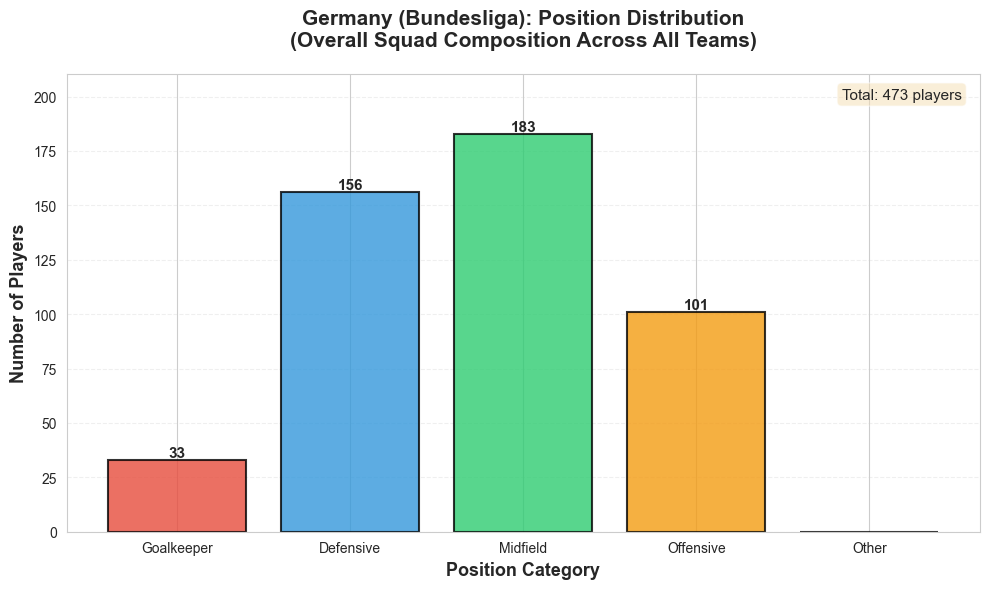


Figure saved: f:\src_FHNW\Semester 3\SAN\reports\figures\LE4\germany_position_distribution.png


In [ ]:
# Create Germany (Bundesliga) position distribution figure
# This figure shows the overall position distribution across all players in the German league
# to provide baseline context for community analysis

print("\n=== Germany (Bundesliga) Position Distribution ===\n")

# Collect position distribution for all players in the pass network
germany_positions = {'Goalkeeper': 0, 'Defensive': 0, 'Midfield': 0, 'Offensive': 0, 'Other': 0}

for node in G_pass_undirected.nodes():
    position = G_pass_undirected.nodes[node].get('position_role', 'Unknown')
    category = categorize_position(position)
    germany_positions[category] += 1

# Print statistics
total_players = G_pass_undirected.number_of_nodes()
print(f"Total players in German league network: {total_players}")
print("\nPosition distribution:")
for pos, count in sorted(germany_positions.items(), key=lambda x: x[1], reverse=True):
    pct = (count / total_players) * 100
    print(f"  {pos}: {count} players ({pct:.1f}%)")

# Create visualization
fig, ax = plt.subplots(figsize=(10, 6))

# Prepare data for bar chart
positions = list(germany_positions.keys())
counts = list(germany_positions.values())
colors_map = {'Goalkeeper': '#e74c3c', 'Defensive': '#3498db', 'Midfield': '#2ecc71', 
              'Offensive': '#f39c12', 'Other': '#95a5a6'}
bar_colors = [colors_map[pos] for pos in positions]

# Create bar chart
bars = ax.bar(positions, counts, color=bar_colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    if height > 0:
        ax.text(bar.get_x() + bar.get_width()/2., height,
               f'{int(height)}',
               ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_xlabel('Position Category', fontsize=13, fontweight='bold')
ax.set_ylabel('Number of Players', fontsize=13, fontweight='bold')
ax.set_title('Germany (Bundesliga): Position Distribution\n(Overall Squad Composition Across All Teams)', 
             fontsize=15, fontweight='bold', pad=20)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.set_ylim(0, max(counts) * 1.15)

# Add total count annotation
ax.text(0.98, 0.97, f'Total: {total_players} players', 
        transform=ax.transAxes, fontsize=11,
        verticalalignment='top', horizontalalignment='right',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()

# Save figure
output_path = project_root / 'reports' / 'figures' / 'LE4' / 'germany_position_distribution.png'
plt.savefig(output_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nFigure saved: {output_path}")

In [ ]:
# Berechne "Position Homogeneity" für jede Community
# Messe wie homogen die Positionen in einer Community sind
print("=== Position Homogeneity Analyse ===\n")

for idx, comm in enumerate(sorted(communities_team, key=len, reverse=True)):
    # Sammle Positionen
    positions = []
    for node in comm:
        position = G_team.nodes[node].get('position_role', 'Unknown')
        category = categorize_position(position)
        positions.append(category)
    
    # Berechne Entropy als Maß für Heterogenität
    pos_counts = Counter(positions)
    total = len(positions)
    entropy = -sum((count/total) * np.log2(count/total) for count in pos_counts.values())
    max_entropy = np.log2(len(pos_counts)) if len(pos_counts) > 1 else 1
    normalized_entropy = entropy / max_entropy if max_entropy > 0 else 0
    
    # Homogeneity = 1 - normalized_entropy (1 = sehr homogen, 0 = sehr heterogen)
    homogeneity = 1 - normalized_entropy
    
    # Dominante Position
    dominant_pos = pos_counts.most_common(1)[0]
    
    print(f"Community {idx+1}:")
    print(f"  Größe: {len(comm)} Spieler")
    print(f"  Dominante Position: {dominant_pos[0]} ({dominant_pos[1]}/{total})")
    print(f"  Position Homogeneity: {homogeneity:.3f} (1=homogen, 0=heterogen)")
    print(f"  Entropy: {entropy:.3f} (max={max_entropy:.3f})")
    print()

=== Position Homogeneity Analyse ===

Community 1:
  Größe: 15 Spieler
  Dominante Position: Defensive (8/15)
  Position Homogeneity: 0.117 (1=homogen, 0=heterogen)
  Entropy: 1.400 (max=1.585)

Community 2:
  Größe: 8 Spieler
  Dominante Position: Defensive (3/8)
  Position Homogeneity: 0.015 (1=homogen, 0=heterogen)
  Entropy: 1.561 (max=1.585)

Community 3:
  Größe: 6 Spieler
  Dominante Position: Defensive (3/6)
  Position Homogeneity: 0.079 (1=homogen, 0=heterogen)
  Entropy: 1.459 (max=1.585)

Community 4:
  Größe: 2 Spieler
  Dominante Position: Offensive (1/2)
  Position Homogeneity: 0.000 (1=homogen, 0=heterogen)
  Entropy: 1.000 (max=1.000)

